# 上頬 ROI：ムラと乾燥感候補を分けて確認する

既存の rank 解析結果 `summary.json` を再利用し、候補選定は変更しません。\n
低周波の明度・色ムラ、高周波の細かな質感、細い暗線候補を別々に表示します。\n
細線候補は画像上の目立ちであり、物理的なシワ深さや臨床的な乾燥診断ではありません。\n

In [1]:
from pathlib import Path
import os
import sys

cwd = Path.cwd().resolve()
marker = Path('analysis/review_upper_cheek_skin.py')
if (cwd / marker).is_file():
    REPO_ROOT = cwd
elif cwd.name == 'notebooks' and (cwd.parent / marker).is_file():
    REPO_ROOT = cwd.parent
    os.chdir(REPO_ROOT)
else:
    raise RuntimeError(f'ikiikimake のリポジトリ直下または notebooks/ から実行してください: current={cwd}')
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
print('repo root:', Path.cwd())


repo root: C:\Users\mail\work\ikiikimake


pairs: 14
html: C:\Users\mail\work\ikiikimake\outputs\makeup0923\eye_texture_rank_validation\upper_cheek_dryness_report.html
csv: C:\Users\mail\work\ikiikimake\outputs\makeup0923\eye_texture_rank_validation\upper_cheek_dryness_metrics.csv


指標,before,after,after - before
低周波明度ムラ（L* MAD）,3.665,2.404,-1.260
低周波色ムラ（ab MAD）,2.043,0.636,-1.408
細かな質感コントラスト（中央値）,0.131,0.244,+0.113
細かな質感コントラスト（p90）,0.302,0.887,+0.585
細線候補・暗さコントラスト（p95）,0.455,2.209,+1.753
指標,before,after,after - before
低周波明度ムラ（L* MAD）,2.376,1.600,-0.775
低周波色ムラ（ab MAD）,2.435,1.689,-0.746
細かな質感コントラスト（中央値）,0.102,0.178,+0.076
細かな質感コントラスト（p90）,0.262,0.506,+0.243

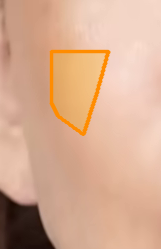
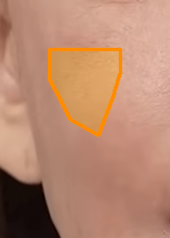
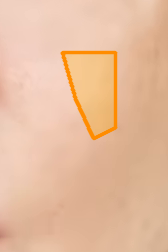
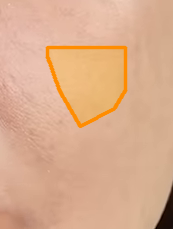
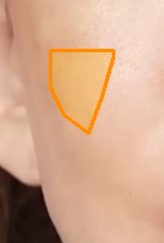
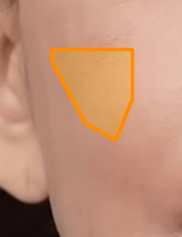
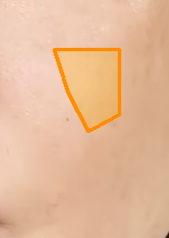
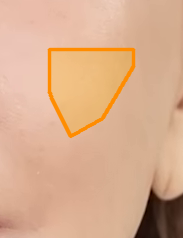
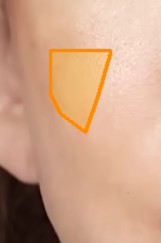
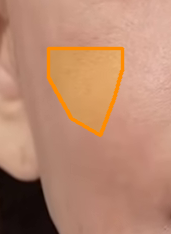
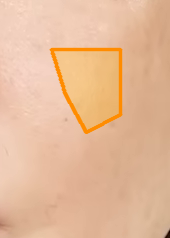
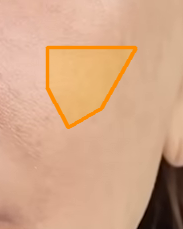
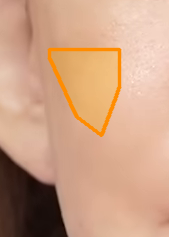
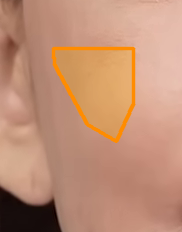
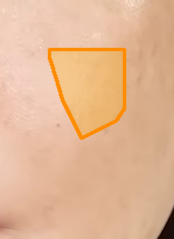
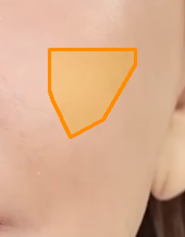
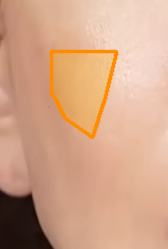
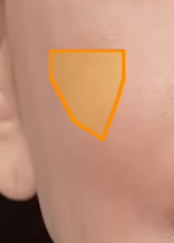
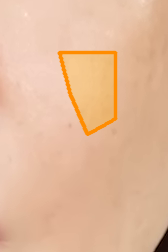
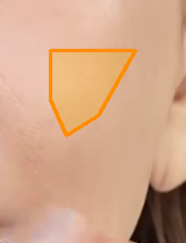
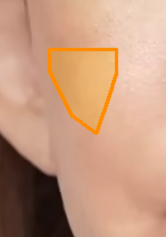
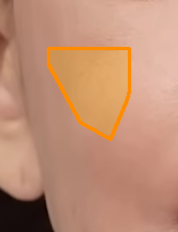
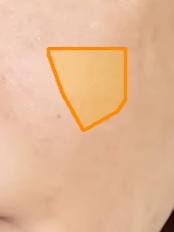
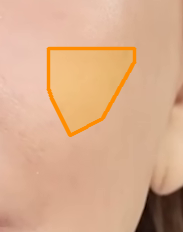
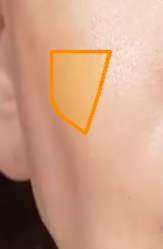
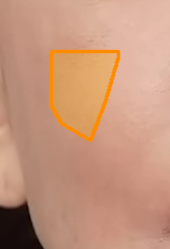
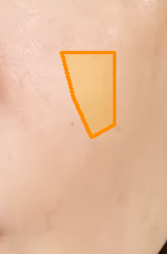
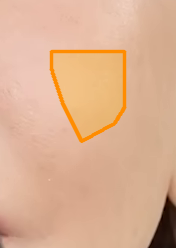
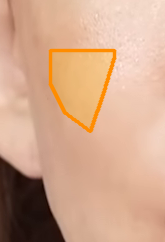
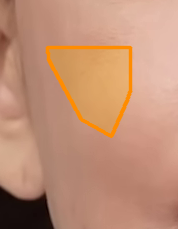
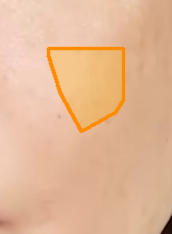
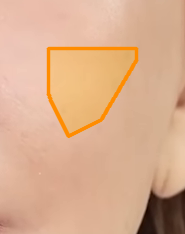
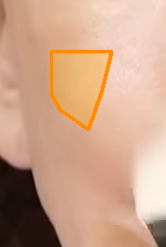
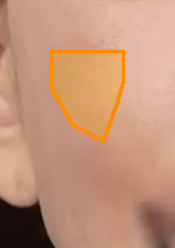
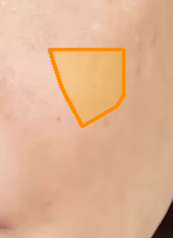
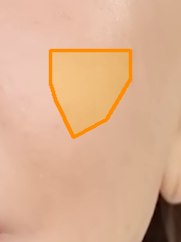
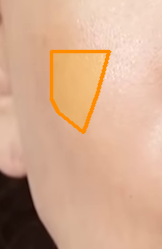
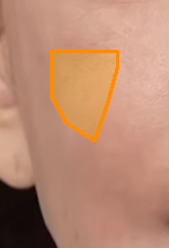
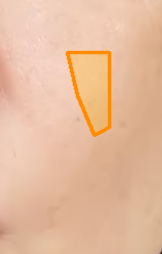
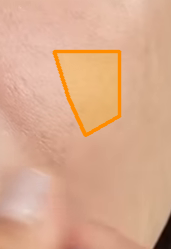
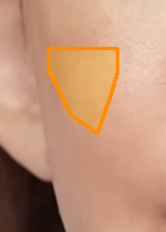
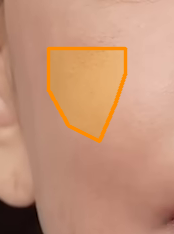
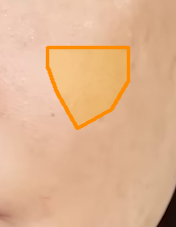
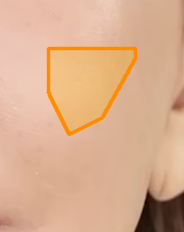
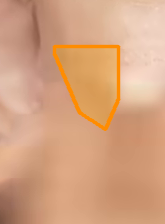
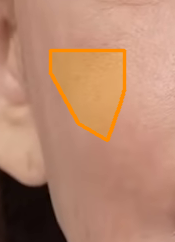
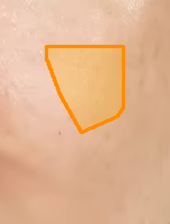
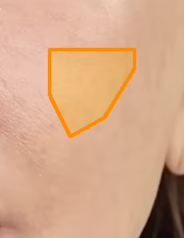
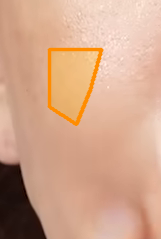
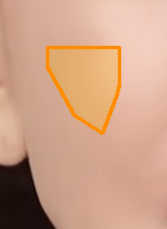
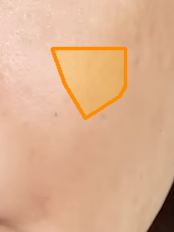
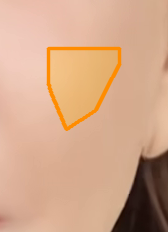
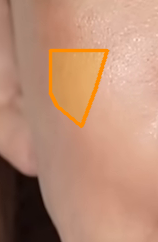
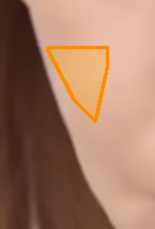
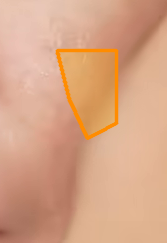
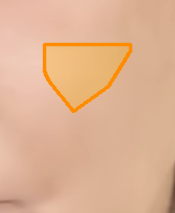

[{'metric': 'lowfreq_L_mad',
  'side': '画面左',
  'n': 14,
  'positive': 1,
  'negative': 13,
  'zero': 0,
  'median_delta': -0.5347464472854},
 {'metric': 'lowfreq_L_mad',
  'side': '画面右',
  'n': 14,
  'positive': 0,
  'negative': 14,
  'zero': 0,
  'median_delta': -0.6503351273743689},
 {'metric': 'lowfreq_ab_mad',
  'side': '画面左',
  'n': 14,
  'positive': 0,
  'negative': 14,
  'zero': 0,
  'median_delta': -0.9392837444325954},
 {'metric': 'lowfreq_ab_mad',
  'side': '画面右',
  'n': 14,
  'positive': 0,
  'negative': 14,
  'zero': 0,
  'median_delta': -1.1825762821582084},
 {'metric': 'highpass_median_pct',
  'side': '画面左',
  'n': 14,
  'positive': 8,
  'negative': 6,
  'zero': 0,
  'median_delta': 0.0126863098399837},
 {'metric': 'highpass_median_pct',
  'side': '画面右',
  'n': 14,
  'positive': 4,
  'negative': 10,
  'zero': 0,
  'median_delta': -0.017672089841624973},
 {'metric': 'highpass_p90_pct',
  'side': '画面左',
  'n': 14,
  'positive': 8,
  'negative': 6,
  'zero': 0,
  'median_de

In [2]:
from IPython.display import HTML, display
from analysis.review_upper_cheek_skin import analyze_upper_cheek_review

SUMMARY = Path('outputs/makeup0923/eye_texture_rank_validation/summary.json')
if not SUMMARY.is_file():
    raise FileNotFoundError(SUMMARY)

result = analyze_upper_cheek_review(SUMMARY)
print('pairs:', result['pairs'])
print('html:', result['output_html'])
print('csv:', result['output_csv'])
display(HTML(Path(result['output_html']).read_text(encoding='utf-8')))
result['sign_summary']
